# Blok 3 · Część 1 — Drzewo decyzyjne

**Uczenie maszynowe w Pythonie** — Politechnika Gdańska, 2026

**Skąd przychodzimy:**
* Na Zajęciach 1 model liniowy nie umiał „zgiąć” zależności — nieliniowość musieliśmy **dokleić sami** (splajny, GAM): RMSE w California spadło z 0.72 do 0.67.
* Na Zajęciach 2 włożyliśmy dużo pracy w **dane** do regresji logistycznej: kody 96/98, winsoryzacja, imputacja. PR-AUC wzrosło z ok. 0.23 do ok. 0.35.

**Dzisiejsze pytanie:** czy istnieje model, który **sam** znajduje nieliniowości i interakcje, i którego nie obchodzą skala ani wartości odstające?

**Plan:**
1. Intuicja — drzewo jako seria pytań
2. Jak drzewo wybiera podział — Gini, entropia, zysk informacji
3. Przeuczenie — i niestabilność drzewa
4. Kontrola złożoności — przycinanie i pierwsze strojenie z `GridSearchCV`
5. Co drzewo daje „za darmo”, a czego nie umie
6. Podsumowanie — i most do części 2

**Dane** — wyłącznie znane z Zajęć 1–2:
* **hotele** (klasyfikacja) — czy rezerwacja zostanie anulowana (`is_canceled`, ok. 37% anulowań),
* **California Housing** (regresja) — mediana wartości domu w dzielnicy (`MedHouseVal`, w setkach tys. USD),
* **Give Me Some Credit** (rzadka klasa) — czy klient spóźni się ze spłatą 90+ dni w ciągu 2 lat (`SeriousDlqin2yrs`, ok. 6,7% defaultów),
* **sinusoida z Zajęć 1** (regresja, dane syntetyczne) — y = sin(x) + szum; znamy prawdę, więc widać przeuczenie.

## 0. Przygotowanie

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import warnings

from sklearn import set_config
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate

warnings.filterwarnings("ignore", category=FutureWarning)
set_config(transform_output="pandas")

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (8, 5)
sns.set_theme(style="whitegrid")

print("scikit-learn", sklearn.__version__)   # drzewa z natywną obsługą NaN: >= 1.4

scikit-learn 1.9.1


In [44]:
# hotele i California: lokalnie z repo, w Colabie z GitHuba
URL = "https://raw.githubusercontent.com/ml-course-pg/ml-course-pg-2026/main/01-wprowadzenie/data/"

def wczytaj(nazwa):
    try:
        return pd.read_csv(f"../01-wprowadzenie/data/{nazwa}")
    except FileNotFoundError:
        return pd.read_csv(URL + nazwa)

# Give Me Some Credit: lokalnie z repo, w Colabie z OpenML
TARGET = "SeriousDlqin2yrs"

def wczytaj_kredyty():
    try:
        from scipy.io import arff
        df = pd.DataFrame(arff.loadarff("../02-ocena-i-dane/data/give-me-some-credit")[0])
    except FileNotFoundError:
        from sklearn.datasets import fetch_openml
        df = fetch_openml(data_id=45577, as_frame=True).frame
    df[TARGET] = df[TARGET].map(lambda v: v.decode() if isinstance(v, bytes) else v).astype(int)
    return df

hotele = wczytaj("hotels.csv")
kalifornia = wczytaj("california_housing.csv")
kredyty_pelne = wczytaj_kredyty()
# ta sama próbka 30 000 co w zadaniu z Zajęć 2
kredyty, _ = train_test_split(kredyty_pelne, train_size=30_000, stratify=kredyty_pelne[TARGET], random_state=RANDOM_STATE)
kredyty = kredyty.reset_index(drop=True)

print("hotele:    ", hotele.shape, f"  anulowanych: {hotele['is_canceled'].mean():.1%}")
print("kalifornia:", kalifornia.shape)
print("kredyty:   ", kredyty.shape, f"  defaultów: {kredyty[TARGET].mean():.1%}")

hotele:     (10000, 28)   anulowanych: 37.0%
kalifornia: (20433, 9)
kredyty:    (30000, 11)   defaultów: 6.7%


Przygotowujemy trzy zestawy `X, y` — te same kolumny co na Zajęciach 1–2. Jedna drobna zmiana w hotelach: `agent` to **identyfikator**, więc od razu zamieniamy go na tekst („ID nigdy jako liczba” — wniosek z Zajęć 2), a brak agenta to osobna kategoria `"brak"` (rezerwacja bezpośrednia).

In [45]:
# --- hotele (klasyfikacja) ---
CECHY_NUM = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
             "adults", "children", "babies", "is_repeated_guest",
             "previous_cancellations", "previous_bookings_not_canceled",
             "days_in_waiting_list", "adr",
             "required_car_parking_spaces", "total_of_special_requests"]
CECHY_KAT = ["hotel", "meal", "market_segment", "distribution_channel",
             "reserved_room_type", "deposit_type", "customer_type", "country", "agent"]

X_hot = hotele[CECHY_NUM + CECHY_KAT].copy()
X_hot["agent"] = hotele["agent"].fillna(0).astype(int).astype(str).replace("0", "brak")
X_hot["country"] = X_hot["country"].fillna("brak")
y_hot = hotele["is_canceled"]

# --- California (regresja) ---
kalifornia["BedrmsShare"] = kalifornia["AveBedrms"] / kalifornia["AveRooms"]   # cecha z Zajęć 1
X_kal = kalifornia.drop(columns="MedHouseVal")
y_kal = kalifornia["MedHouseVal"]

# --- Give Me Some Credit (rzadka klasa) ---
X_kred = kredyty.drop(columns=TARGET)
y_kred = kredyty[TARGET]

# jeden obiekt cv na zbiór — wszystkie warianty na tych samych foldach (zasada z Zajęć 2)
cv_hot = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_kal = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_kred = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Pomocnicza funkcja: CV → **średnia ± odchylenie** na walidacji oraz wynik na treningu („termometr przeuczenia” z Zajęć 1). Wyniki zbieramy w jednej tabeli, do której wrócimy w podsumowaniu.

In [46]:
TABELA = []

def ocen(nazwa, model, X, y, cv, metryka, zbior, pokaz=True):
    r = cross_validate(model, X, y, cv=cv, scoring=metryka, return_train_score=True, n_jobs=-1)
    znak = -1 if metryka.startswith("neg_") else 1
    wiersz = {"zbiór": zbior, "model": nazwa,
              "metryka": metryka.replace("neg_", ""),
              "walidacja": znak * r["test_score"].mean(),
              "± std": r["test_score"].std(),
              "trening": znak * r["train_score"].mean()}
    TABELA.append(wiersz)
    if pokaz:
        print(f"{nazwa:<45} {wiersz['metryka']}: {wiersz['walidacja']:.4f} ± {wiersz['± std']:.4f}   (trening: {wiersz['trening']:.4f})")
    return wiersz

Punkty odniesienia z poprzednich zajęć — liczymy je jeszcze raz, na tych samych foldach. Pipeline'y są **dokładnie** te z Zajęć 1–2 (skrócone).

In [47]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer, SplineTransformer
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.base import BaseEstimator, TransformerMixin

# hotele: regresja logistyczna z Zajęć 1–2
lr_hotele = Pipeline([
    ("preprocessing", ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"),
                              FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), CECHY_NUM),
        ("kat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False), CECHY_KAT),
    ])),
    ("model", LogisticRegression(max_iter=2000)),
])

# kredyty: najlepszy pipeline z rozwiązania zadania z Zajęć 2
OPOZNIENIA = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]

def kody_na_braki(X):
    X = X.copy()
    for c in OPOZNIENIA:
        X.loc[X[c] >= 96, c] = np.nan
    return X

class Winsoryzacja(BaseEstimator, TransformerMixin):
    # przycina każdą kolumnę do kwantyli [q, 1-q] wyznaczonych na danych treningowych
    def __init__(self, q=0.01):
        self.q = q
    def fit(self, X, y=None):
        A = np.asarray(X, dtype=float)
        self.dolne_ = np.nanquantile(A, self.q, axis=0)
        self.gorne_ = np.nanquantile(A, 1 - self.q, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.dolne_, self.gorne_)
    def set_output(self, *, transform=None):
        return self

lr_kredyty_surowe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=3000))
lr_kredyty_najlepsze = make_pipeline(FunctionTransformer(kody_na_braki), SimpleImputer(strategy="median", add_indicator=True),
                                     Winsoryzacja(0.01), StandardScaler(), LogisticRegression(max_iter=3000))

print("HOTELE (ROC-AUC)")
ocen("Dummy", DummyClassifier(), X_hot, y_hot, cv_hot, "roc_auc", "hotele")
ocen("regresja logistyczna (Zajęcia 1–2)", lr_hotele, X_hot, y_hot, cv_hot, "roc_auc", "hotele")
print("\nCALIFORNIA (RMSE)")
ocen("Dummy", DummyRegressor(), X_kal, y_kal, cv_kal, "neg_root_mean_squared_error", "kalifornia")
ocen("regresja liniowa", make_pipeline(StandardScaler(), LinearRegression()), X_kal, y_kal, cv_kal, "neg_root_mean_squared_error", "kalifornia")
ocen("GAM: splajny + Ridge (Zajęcia 1)", make_pipeline(StandardScaler(), SplineTransformer(n_knots=8, degree=3), Ridge(alpha=1.0)),
     X_kal, y_kal, cv_kal, "neg_root_mean_squared_error", "kalifornia")
print("\nKREDYTY (PR-AUC)")
ocen("Dummy", DummyClassifier(), X_kred, y_kred, cv_kred, "average_precision", "kredyty")
ocen("LR: surowe dane (mediana + skalowanie)", lr_kredyty_surowe, X_kred, y_kred, cv_kred, "average_precision", "kredyty")
ocen("LR: najlepsze z Zajęć 2 (kody + winsoryzacja)", lr_kredyty_najlepsze, X_kred, y_kred, cv_kred, "average_precision", "kredyty");

HOTELE (ROC-AUC)
Dummy                                         roc_auc: 0.5000 ± 0.0000   (trening: 0.5000)
regresja logistyczna (Zajęcia 1–2)            roc_auc: 0.9095 ± 0.0057   (trening: 0.9164)

CALIFORNIA (RMSE)
Dummy                                         root_mean_squared_error: 1.1542 ± 0.0213   (trening: 1.1543)
regresja liniowa                              root_mean_squared_error: 0.7216 ± 0.0184   (trening: 0.7164)
GAM: splajny + Ridge (Zajęcia 1)              root_mean_squared_error: 0.6658 ± 0.0153   (trening: 0.6604)

KREDYTY (PR-AUC)
Dummy                                         average_precision: 0.0668 ± 0.0000   (trening: 0.0668)
LR: surowe dane (mediana + skalowanie)        average_precision: 0.2260 ± 0.0079   (trening: 0.2277)
LR: najlepsze z Zajęć 2 (kody + winsoryzacja) average_precision: 0.3542 ± 0.0145   (trening: 0.3547)


To są liczby do pobicia. Zapamiętajcie szczególnie **różnicę między surowymi a przygotowanymi danymi w kredytach** — wrócimy do niej w sekcji 5.

---
## 1. Intuicja: drzewo jako seria pytań

### 1.1 Gra w „20 pytań” na hotelach

Wyobraźcie sobie, że recepcjonista z 20-letnim stażem ma zgadnąć, czy rezerwacja zostanie anulowana. Zadaje **pytania tak/nie**, zaczynając od tego, które najwięcej mówi. Jakie byłoby pierwsze?

In [48]:
print(hotele.groupby("deposit_type")["is_canceled"].agg(odsetek_anulowan="mean", liczba="size").round(3))
print()
print(hotele.groupby(pd.cut(hotele["lead_time"], [-1, 7, 30, 90, 180, 365, 800]), observed=True)["is_canceled"]
      .agg(odsetek_anulowan="mean", liczba="size").round(3))

              odsetek_anulowan  liczba
deposit_type                          
No Deposit               0.285    8782
Non Refund               0.996    1207
Refundable               0.000      11

            odsetek_anulowan  liczba
lead_time                           
(-1, 7]                0.101    1635
(7, 30]                0.260    1618
(30, 90]               0.372    2525
(90, 180]              0.458    2235
(180, 365]             0.572    1749
(365, 800]             0.651     238


Dwa mocne sygnały:
* **„Non Refund” → ok. 99,6% anulowań.** Jedno pytanie i 1 200 rezerwacji jest prawie pewnych.
* **`lead_time`** — im wcześniej ktoś rezerwuje, tym częściej anuluje (10% przy ≤ 7 dniach, 65% przy > rok).

Ręcznie narysowane drzewo mogłoby wyglądać tak:

```
                    deposit_type == "Non Refund"?
                   /                              \
                 tak                              nie
          anuluje (99,6%)                  lead_time > 90 dni?
                                          /                  \
                                        tak                  nie
                               częściej anuluje       rzadziej anuluje
```

**Słownik:**
| pojęcie | znaczenie |
|---|---|
| **korzeń** | pierwsze pytanie — cały zbiór |
| **węzeł** / **podział** | pytanie postaci „cecha ≤ próg?” (dla kategorii: „należy do grupy?”) |
| **liść** | koniec ścieżki — tu zapada decyzja |
| **głębokość** | liczba pytań od korzenia do liścia |
| **predykcja w liściu** | klasyfikacja: klasa większościowa, a `predict_proba` = **odsetek klas w liściu**; regresja: **średnia** targetu w liściu |

Zobaczmy, co wybierze algorytm. Drzewa w scikit-learn potrzebują liczb, więc kategorie zamieniamy `OrdinalEncoder`em (drzewo nie mnoży kodu przez wagę jak model liniowy, tylko pyta „kod ≤ próg?” — kilkoma takimi pytaniami wydzieli dowolną kategorię; szczegóły w sekcji 5).

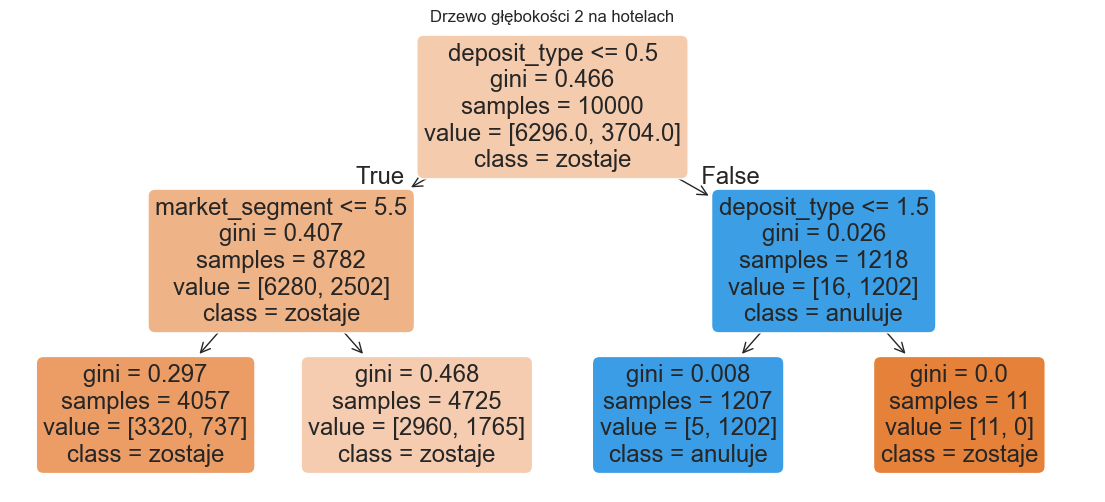

kody deposit_type: {0: 'No Deposit', 1: 'Non Refund', 2: 'Refundable'}


In [49]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
#zoptymalizowana wersja algorytmu CART (Classification And Regression Trees, Breiman i in., 1984)
from sklearn.preprocessing import OrdinalEncoder

def preprocessing_drzewa():
    # kategorie -> liczby całkowite; reszta kolumn bez zmian (bez skalowania, bez imputacji!)
    return ColumnTransformer(
        [("kategorie", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CECHY_KAT)],
        remainder="passthrough", verbose_feature_names_out=False)

drzewo_2 = make_pipeline(preprocessing_drzewa(), DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE))
drzewo_2.fit(X_hot, y_hot)

plt.figure(figsize=(14, 6))
plot_tree(drzewo_2[-1], feature_names=list(drzewo_2[0].get_feature_names_out()),
          class_names=["zostaje", "anuluje"], filled=True, rounded=True, impurity=True, proportion=False)
plt.title("Drzewo głębokości 2 na hotelach")
plt.show()

kody_depozytu = drzewo_2[0].named_transformers_["kategorie"].categories_[CECHY_KAT.index("deposit_type")]
print("kody deposit_type:", dict(enumerate(kody_depozytu)))

Algorytm sam wybrał **`deposit_type`** jako pierwsze pytanie — tak jak my. `deposit_type <= 0.5` oznacza „No Deposit” (kod 0), a dwa podziały po kodach wydzielają „Non Refund” (kod 1). Każdy węzeł pokazuje: `gini` (za chwilę), liczbę rezerwacji (`samples`) i ile jest w każdej klasie (`value`).

To samo w wersji tekstowej — gotowe **reguły biznesowe**, które można wkleić do maila:

In [50]:
print(export_text(drzewo_2[-1], feature_names=list(drzewo_2[0].get_feature_names_out()), show_weights=True))

|--- deposit_type <= 0.50
|   |--- market_segment <= 5.50
|   |   |--- weights: [3320.00, 737.00] class: 0
|   |--- market_segment >  5.50
|   |   |--- weights: [2960.00, 1765.00] class: 0
|--- deposit_type >  0.50
|   |--- deposit_type <= 1.50
|   |   |--- weights: [5.00, 1202.00] class: 1
|   |--- deposit_type >  1.50
|   |   |--- weights: [11.00, 0.00] class: 0



### 1.2 Widok geometryczny: drzewo tnie przestrzeń na prostokąty

Każde pytanie „cecha ≤ próg” to **cięcie prostopadłe do osi**. Najlepiej to widać na mapie: California, tylko dwie cechy — `Longitude` i `Latitude` — a kolor to cena.

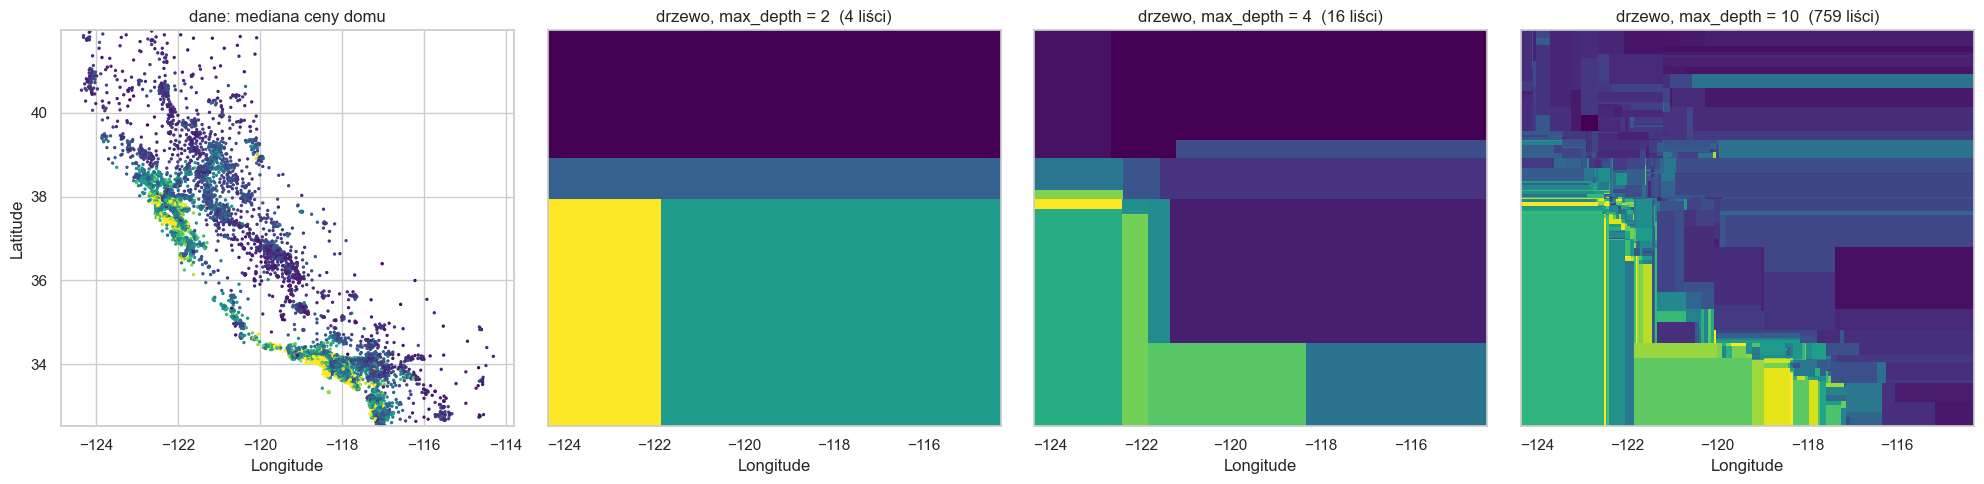

In [51]:
xx, yy = np.meshgrid(np.linspace(X_kal["Longitude"].min(), X_kal["Longitude"].max(), 300),
                     np.linspace(X_kal["Latitude"].min(), X_kal["Latitude"].max(), 300))
siatka = pd.DataFrame({"Longitude": xx.ravel(), "Latitude": yy.ravel()})

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
axes[0].scatter(X_kal["Longitude"], X_kal["Latitude"], c=y_kal, cmap="viridis", s=2)
axes[0].set_title("dane: mediana ceny domu")
for ax, glebokosc in zip(axes[1:], [2, 4, 10]):
    d = DecisionTreeRegressor(max_depth=glebokosc, random_state=RANDOM_STATE).fit(X_kal[["Longitude", "Latitude"]], y_kal)
    ax.pcolormesh(xx, yy, d.predict(siatka).reshape(xx.shape), cmap="viridis", shading="auto")
    ax.set_title(f"drzewo, max_depth = {glebokosc}  ({d.get_n_leaves()} liści)")
for ax in axes:
    ax.set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
plt.tight_layout(); plt.show()

* Głębokość 2 → 4 prostokąty. Głębokość 4 → 16 i już widać wybrzeże (drogie) vs interior (tanie). Głębokość 10 → setki prostokątów, które odtwarzają Bay Area i Los Angeles.
* W każdym prostokącie predykcja jest **stała** = średnia cena dzielnic, które w nim leżą.
* Zauważcie: drzewo **samo** znalazło interakcję „długość × szerokość geograficzna”. Model liniowy widzi każdą z nich osobno — „im dalej na zachód, tym drożej” — i nie potrafi narysować wyspy drogich cen wokół miasta.

## 2. Jak drzewo wybiera podział

### 2.1 Miara „bałaganu” w węźle: Gini i entropia

Dobry podział to taki, po którym dzieci są **czystsze** niż rodzic — najlepiej każde z jedną klasą. Potrzebujemy liczby, która mierzy „nieczystość” (*impurity*). Dla odsetka klasy pozytywnej $p$ w węźle:

| miara | wzór (2 klasy) | czysty węzeł ($p=0$ lub $1$) | największy bałagan ($p=0.5$) |
|---|---|---|---|
| **Gini** | $2p(1-p)$ | 0 | 0.5 |
| **entropia** | $-p\log_2 p - (1-p)\log_2(1-p)$ | 0 | 1 |

**Gini — „jak często się pomylę, zgadując na ślepo?”**

Losujemy rezerwację z węzła i zgadujemy jej etykietę losowo, zgodnie z proporcjami w węźle. Gini to prawdopodobieństwo pomyłki:

* rezerwacja anuluje, a my mówimy „zostaje”: $p \cdot (1-p)$,
* rezerwacja zostaje, a my mówimy „anuluje”: $(1-p) \cdot p$,
* razem: $2p(1-p)$.

Przykłady z hoteli: korzeń (37% anulowań) → $2 \cdot 0.37 \cdot 0.63 \approx 0.47$, czyli prawie co drugi strzał chybiony. Węzeł „Non Refund” (99,6% anulowań) → $\approx 0.008$, czyli prawie nigdy.

**Entropia — „ile pytań tak/nie potrzebuję, żeby poznać etykietę?”**

Entropia mierzy niepewność w **bitach**, czyli w liczbie pytań tak/nie:

* $p = 0.5$ — zupełnie nie wiemy, co będzie → 1 pełne pytanie (**1 bit**),
* $p = 0$ lub $1$ — wiemy z góry → pytania są zbędne (**0 bitów**),
* $p = 0.37$ — wiemy trochę („raczej zostaje”), ale niewiele → ok. **0.95 bita**.

**Po co dwie miary?** To **alternatywy** — drzewo używa jednej (`criterion="gini"` albo `"entropy"`). Gini pochodzi z algorytmu CART (statystyka), entropia — z teorii informacji (algorytmy ID3/C4.5). Obie rosną i maleją w tych samych sytuacjach, więc prawie zawsze wybierają ten sam podział (sprawdzimy w 2.5). Domyślny w sklearn jest Gini, bo liczy się szybciej.

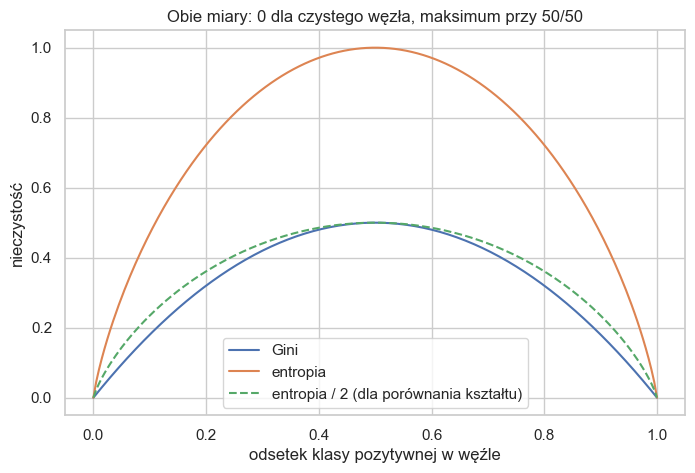

In [52]:
def gini(p):
    return 2 * p * (1 - p)

def entropia(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

p = np.linspace(0, 1, 201)
plt.plot(p, gini(p), label="Gini")
plt.plot(p, entropia(p), label="entropia")
plt.plot(p, entropia(p) / 2, "--", label="entropia / 2 (dla porównania kształtu)")
plt.xlabel("odsetek klasy pozytywnej w węźle"); plt.ylabel("nieczystość")
plt.title("Obie miary: 0 dla czystego węzła, maksimum przy 50/50")
plt.legend(); plt.show()

**Co widać na wykresie:**

* **Minimum = 0 tylko na brzegach** — przy $p = 0$ (same „zostaje”) albo $p = 1$ (same „anuluje”). To jest **czysty węzeł**: wiemy na pewno, jaka jest etykieta.
* **Maksimum dokładnie w środku** ($p = 0.5$) — pół na pół, największy bałagan.
* **Obie krzywe są symetryczne** względem $p = 0.5$ — węzeł z 10% anulowań jest tak samo „brudny” jak węzeł z 90% anulowań. Miara nie obchodzi, *która* klasa przeważa, tylko *jak bardzo* przeważa.
* **Entropia / 2 prawie pokrywa się z Gini** — różnią się głównie skalą, kształt jest niemal ten sam. Dlatego prawie zawsze wybierają ten sam podział.

### 2.2 Zysk informacji — policzmy ręcznie

**Zysk informacji** = nieczystość rodzica − **ważona** nieczystość dzieci. Drzewo wybiera podział z **największym zyskiem**.

**Przykład:** węzeł z 10 rezerwacjami, z czego 4 anulowane.

**Rodzic:** $p = \frac{4}{10} = 0.4$

$$\text{Gini}_{\text{rodzic}} = 2 \cdot 0.4 \cdot 0.6 = 0.48$$

---

**Podział A:** lewe dziecko — 4 rezerwacje (3 anulowane), prawe — 6 rezerwacji (1 anulowana).

$$\text{Gini}_{\text{lewe}} = 2 \cdot \tfrac{3}{4} \cdot \tfrac{1}{4} = 0.375 \qquad \text{Gini}_{\text{prawe}} = 2 \cdot \tfrac{1}{6} \cdot \tfrac{5}{6} \approx 0.278$$

Średnia ważona liczebnością (lewe ma 4 z 10 rezerwacji, prawe 6 z 10):

$$\tfrac{4}{10} \cdot 0.375 + \tfrac{6}{10} \cdot 0.278 \approx 0.150 + 0.167 = 0.317$$

$$\text{zysk}_A = 0.48 - 0.317 \approx \mathbf{0.163}$$

---

**Podział B:** odcinamy **jedną** anulowaną rezerwację do osobnego liścia; zostaje 9 rezerwacji (3 anulowane).

$$\text{Gini}_{\text{lewe}} = 0 \;\text{(czysty liść!)} \qquad \text{Gini}_{\text{prawe}} = 2 \cdot \tfrac{3}{9} \cdot \tfrac{6}{9} \approx 0.444$$

$$\tfrac{1}{10} \cdot 0 + \tfrac{9}{10} \cdot 0.444 = 0.400$$

$$\text{zysk}_B = 0.48 - 0.400 = \mathbf{0.080}$$

---

**Wniosek:** wygrywa **podział A**, choć żadne z jego dzieci nie jest czyste. Podział B ma czysty liść, ale tylko z jedną rezerwacją — a ważenie liczebnością sprawia, że mały czysty liść wnosi niewiele. Dla drzewa liczy się, ile danych udało się „uporządkować”, a nie to, czy gdzieś powstał idealny liść.

In [53]:
def zysk_gini(y_rodzic, maska_lewa):
    y_l, y_p = y_rodzic[maska_lewa], y_rodzic[~maska_lewa]
    w_l = len(y_l) / len(y_rodzic)
    return gini(y_rodzic.mean()) - (w_l * gini(y_l.mean()) + (1 - w_l) * gini(y_p.mean()))

### 2.3 Algorytm: sprawdź wszystko, weź najlepsze — i powtórz

Dla **każdej** cechy i **każdego** możliwego progu liczymy zysk. Zobaczmy to dla jednej cechy — `lead_time`:

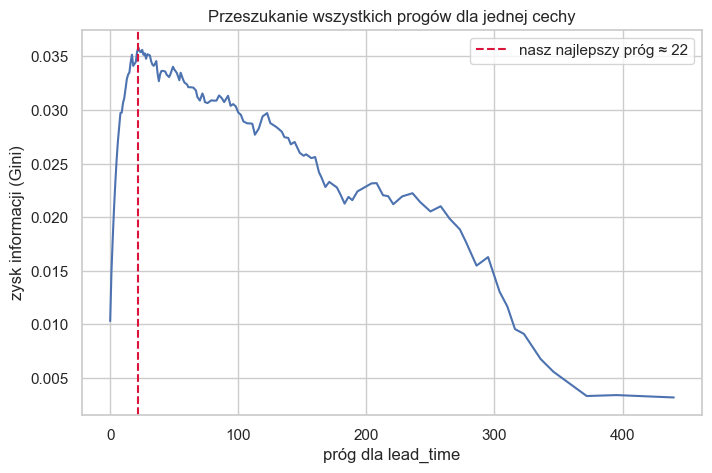

próg wybrany przez sklearn: 22.5


In [54]:
progi = np.unique(np.quantile(X_hot["lead_time"], np.linspace(0.01, 0.99, 150)))
zyski = [zysk_gini(y_hot, X_hot["lead_time"] <= t) for t in progi]
najlepszy = progi[int(np.argmax(zyski))]

d1 = DecisionTreeClassifier(max_depth=1).fit(X_hot[["lead_time"]], y_hot)

plt.plot(progi, zyski)
plt.axvline(najlepszy, color="crimson", ls="--", label=f"nasz najlepszy próg ≈ {najlepszy:.0f}")
plt.xlabel("próg dla lead_time"); plt.ylabel("zysk informacji (Gini)")
plt.title("Przeszukanie wszystkich progów dla jednej cechy")
plt.legend(); plt.show()
print(f"próg wybrany przez sklearn: {d1.tree_.threshold[0]:.1f}")

Nasza pętla i sklearn wybrały ten sam próg (sklearn bierze środek między sąsiednimi wartościami). Pełny algorytm:

1. Dla każdej cechy i progu policz zysk; wybierz **najlepszy** podział.
2. Podziel dane na dwoje.
3. **Rekurencyjnie** powtórz kroki 1–2 w każdym dziecku — dopóki nie zadziała warunek stopu (sekcja 4).

To algorytm **zachłanny** — w każdym kroku bierze to, co najlepsze *teraz*, nie patrząc w przyszłość. Nie gwarantuje najlepszego drzewa globalnie (znalezienie go jest obliczeniowo bardzo ciezkie)

### 2.4 Regresja: zamiast Gini — błąd średniokwadratowy

W regresji „bałagan” w węźle to **wariancja** targetu (MSE względem średniej), a predykcja w liściu to **średnia**. Podział dobieramy tak, żeby **najbardziej zmniejszyć MSE**. Na sinusoidzie z Zajęć 1 — drzewo z jednym pytaniem:

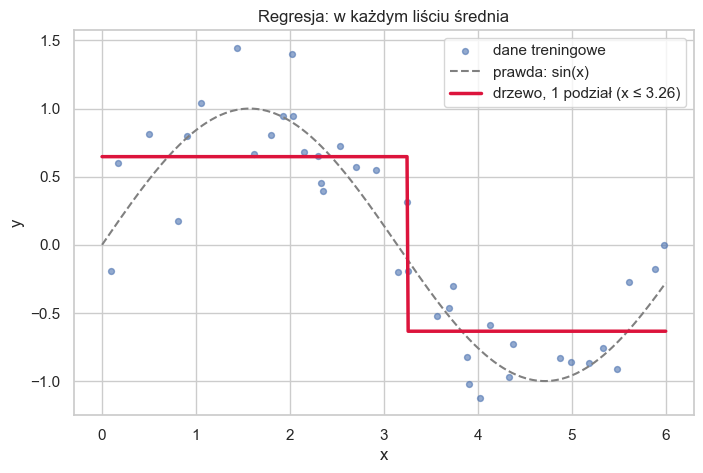

In [55]:
# te same dane syntetyczne co na Zajęciach 1: znamy prawdę (sinus)
rng = np.random.default_rng(0)
Xs = np.sort(rng.uniform(0, 6, size=60)).reshape(-1, 1)
ys = np.sin(Xs).ravel() + rng.normal(0, 0.25, size=60)
Xs_tr, Xs_val, ys_tr, ys_val = train_test_split(Xs, ys, test_size=0.35, random_state=RANDOM_STATE)
siatka_s = np.linspace(0, 6, 500).reshape(-1, 1)

pien = DecisionTreeRegressor(max_depth=1).fit(Xs_tr, ys_tr)
prog = pien.tree_.threshold[0]
plt.scatter(Xs_tr, ys_tr, s=18, alpha=0.6, label="dane treningowe")
plt.plot(siatka_s, np.sin(siatka_s), color="gray", ls="--", label="prawda: sin(x)")
plt.plot(siatka_s, pien.predict(siatka_s), color="crimson", lw=2.5, label=f"drzewo, 1 podział (x ≤ {prog:.2f})")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Regresja: w każdym liściu średnia")
plt.legend(); plt.show()

### 2.5 Gini czy entropia?

W praktyce **prawie zawsze to samo drzewo**. Sprawdźmy w CV (parametr `criterion`):

In [56]:
for kryterium in ["gini", "entropy"]:
    ocen(f"drzewo max_depth=8, criterion='{kryterium}'",
         make_pipeline(preprocessing_drzewa(), DecisionTreeClassifier(max_depth=8, criterion=kryterium, random_state=RANDOM_STATE)),
         X_hot, y_hot, cv_hot, "roc_auc", "hotele", pokaz=True)
TABELA = TABELA[:-2]   # to był tylko test — nie zapisujemy do tabeli końcowej

drzewo max_depth=8, criterion='gini'          roc_auc: 0.8914 ± 0.0077   (trening: 0.9084)
drzewo max_depth=8, criterion='entropy'       roc_auc: 0.8891 ± 0.0085   (trening: 0.9054)


Różnica mieści się w szumie między foldami. **Kryterium nie jest bardzo ważnym hiperparametrem** — ważne jest to, jak duże pozwolimy urosnąć drzewu.

---
## 3. Przeuczenie

### 3.1 Ten sam obrazek co z wielomianami na Zajęciach 1

Na Zajęciach 1 złożoność kontrolował **stopień wielomianu**. Dla drzewa to **głębokość**:

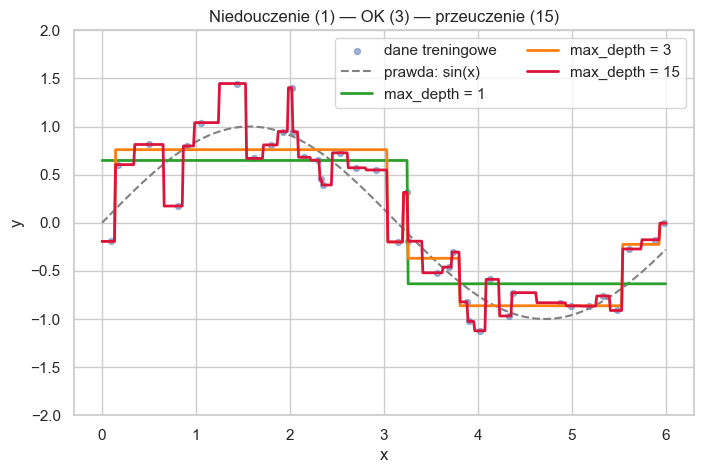

In [57]:
plt.scatter(Xs_tr, ys_tr, s=18, alpha=0.5, label="dane treningowe")
plt.plot(siatka_s, np.sin(siatka_s), color="gray", lw=1.5, ls="--", label="prawda: sin(x)")
for glebokosc, kolor in [(1, "tab:green"), (3, "tab:orange"), (15, "crimson")]:
    d = DecisionTreeRegressor(max_depth=glebokosc, random_state=RANDOM_STATE).fit(Xs_tr, ys_tr)
    plt.plot(siatka_s, d.predict(siatka_s), color=kolor, lw=2, label=f"max_depth = {glebokosc}")
plt.ylim(-2, 2); plt.xlabel("x"); plt.ylabel("y")
plt.title("Niedouczenie (1) — OK (3) — przeuczenie (15)")
plt.legend(ncol=2); plt.show()

Ta sama historia, inny kształt: zamiast gładkich krzywych — **schodki**. Drzewo bez ograniczeń dzieli dane, dopóki każdy liść nie jest czysty — w regresji oznacza to **jeden punkt na liść**, czyli zapamiętanie szumu.

### 3.2 Krzywa U na prawdziwych danych

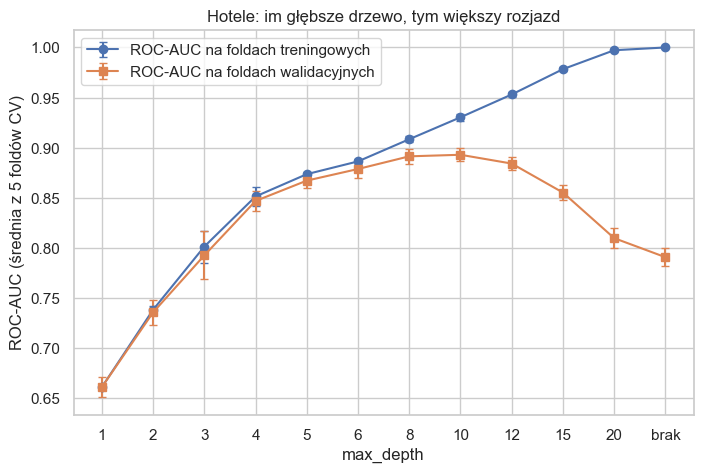

,0,1,2,3,4,5,6,7,8,9,10,11
max_depth,1,2,3,4,5,6,8,10,12,15,20,brak
trening,0.661,0.738,0.801,0.851,0.874,0.886,0.908,0.93,0.953,0.978,0.997,1.0
std trening,0.003,0.004,0.016,0.009,0.002,0.002,0.003,0.003,0.003,0.002,0.0,0.0
walidacja,0.661,0.736,0.792,0.847,0.867,0.879,0.891,0.893,0.884,0.855,0.81,0.791
std walidacja,0.01,0.012,0.024,0.01,0.008,0.009,0.008,0.006,0.007,0.008,0.01,0.009


In [58]:
glebokosci = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
krzywa = []
for g in glebokosci:
    r = cross_validate(make_pipeline(preprocessing_drzewa(), DecisionTreeClassifier(max_depth=g, random_state=RANDOM_STATE)),
                       X_hot, y_hot, cv=cv_hot, scoring="roc_auc", return_train_score=True, n_jobs=-1)
    krzywa.append({"max_depth": "brak" if g is None else str(g),
                   "trening": r["train_score"].mean(), "std trening": r["train_score"].std(),
                   "walidacja": r["test_score"].mean(), "std walidacja": r["test_score"].std()})
krzywa = pd.DataFrame(krzywa)

plt.errorbar(krzywa["max_depth"], krzywa["trening"], yerr=krzywa["std trening"], fmt="o-", capsize=3,
             label="ROC-AUC na foldach treningowych")
plt.errorbar(krzywa["max_depth"], krzywa["walidacja"], yerr=krzywa["std walidacja"], fmt="s-", capsize=3,
             label="ROC-AUC na foldach walidacyjnych")
plt.xlabel("max_depth"); plt.ylabel("ROC-AUC (średnia z 5 foldów CV)")
plt.title("Hotele: im głębsze drzewo, tym większy rozjazd")
plt.legend(); plt.show()
krzywa.round(3).T

* Po lewej **niedouczenie**: kilka pytań to za mało.
* Optimum gdzieś przy **głębokości 8–10**.
* Drzewo bez ograniczeń: ROC-AUC na treningu = **1.0**, a na walidacji spada poniżej drzewa o głębokości 5. Klasyczny termometr przeuczenia z Zajęć 1.

### 3.3 Niestabilność — najważniejsza wada drzewa

Druga twarz wysokiej wariancji: **niewielka zmiana danych → inne drzewo**. Odkładamy 2 000 rezerwacji na bok, a z pozostałych losujemy 5 próbek po 1 000 (rozmiar z Zajęć 2) i na każdej trenujemy to samo drzewo głębokości 3:

In [59]:
X_reszta, X_odlozone, y_reszta, y_odlozone = train_test_split(X_hot, y_hot, test_size=2000, stratify=y_hot, random_state=RANDOM_STATE)

for i in range(5):
    idx = X_reszta.sample(1000, random_state=i).index
    d = make_pipeline(preprocessing_drzewa(), DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)).fit(X_reszta.loc[idx], y_reszta.loc[idx])
    nazwy, t = d[0].get_feature_names_out(), d[-1].tree_
    pytania = [f"{nazwy[t.feature[n]]} ≤ {t.threshold[n]:.1f}" for n in range(t.node_count) if t.feature[n] >= 0]
    print(f"próbka {i}:  " + "  |  ".join(pytania))

próbka 0:  deposit_type ≤ 0.5  |  market_segment ≤ 5.5  |  previous_cancellations ≤ 0.5  |  total_of_special_requests ≤ 0.5  |  is_repeated_guest ≤ 0.5  |  country ≤ 15.0
próbka 1:  deposit_type ≤ 0.5  |  previous_cancellations ≤ 0.5  |  market_segment ≤ 5.5  |  previous_bookings_not_canceled ≤ 5.0
próbka 2:  deposit_type ≤ 0.5  |  market_segment ≤ 5.5  |  country ≤ 37.5  |  total_of_special_requests ≤ 0.5  |  deposit_type ≤ 1.5  |  previous_bookings_not_canceled ≤ 7.5
próbka 3:  deposit_type ≤ 0.5  |  lead_time ≤ 27.5  |  country ≤ 0.5  |  country ≤ 33.5  |  is_repeated_guest ≤ 0.5  |  country ≤ 13.0
próbka 4:  deposit_type ≤ 0.5  |  market_segment ≤ 5.5  |  previous_cancellations ≤ 0.5  |  total_of_special_requests ≤ 0.5  |  deposit_type ≤ 1.5


Korzeń jest zawsze ten sam (bardzo silny sygnał), ale już **drugie i trzecie pytanie** zależą od tego, które rezerwacje trafiły do próbki. 

Ważniejsze niż struktura są **decyzje**. Trenujemy 5 pełnych drzew na 5 próbkach po 80% danych i pytamy je o te same 2 000 odłożonych rezerwacji:

In [60]:
decyzje = []
for i in range(5):
    idx = X_reszta.sample(frac=0.8, random_state=i).index
    d = make_pipeline(preprocessing_drzewa(), DecisionTreeClassifier(random_state=RANDOM_STATE)).fit(X_reszta.loc[idx], y_reszta.loc[idx])
    decyzje.append(d.predict(X_odlozone))
decyzje = np.array(decyzje)

for i, p in enumerate(decyzje):
    print(f"drzewo {i}: accuracy {np.mean(p == y_odlozone):.3f}")
print(f"\nrezerwacje, co do których 5 drzew NIE jest zgodnych: {np.mean(decyzje.min(axis=0) != decyzje.max(axis=0)):.0%}")
print(f"głosowanie większością 5 drzew:   accuracy {np.mean((decyzje.mean(axis=0) > 0.5) == y_odlozone):.3f}")

drzewo 0: accuracy 0.797
drzewo 1: accuracy 0.788
drzewo 2: accuracy 0.791
drzewo 3: accuracy 0.777
drzewo 4: accuracy 0.785

rezerwacje, co do których 5 drzew NIE jest zgodnych: 38%
głosowanie większością 5 drzew:   accuracy 0.815


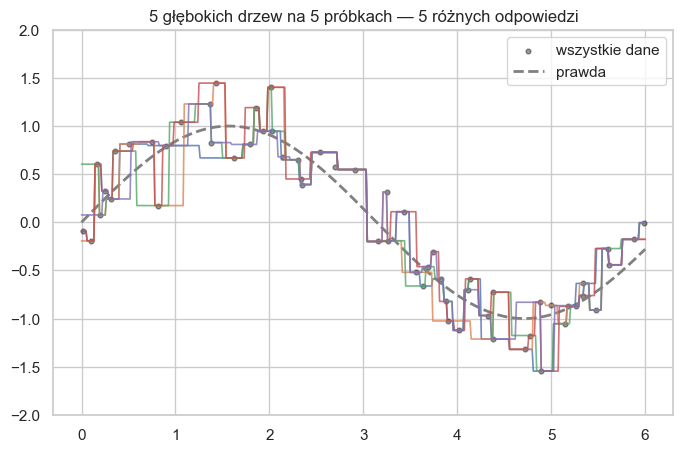

In [61]:
# to samo na sinusoidzie — 5 głębokich drzew na 5 próbkach
plt.scatter(Xs, ys, s=12, alpha=0.4, color="black", label="wszystkie dane")
plt.plot(siatka_s, np.sin(siatka_s), color="gray", ls="--", lw=2, label="prawda")
for i in range(5):
    idx = np.random.default_rng(i).choice(len(Xs), size=len(Xs), replace=True)
    d = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(Xs[idx], ys[idx])
    plt.plot(siatka_s, d.predict(siatka_s), lw=1.2, alpha=0.8)
plt.ylim(-2, 2); plt.title("5 głębokich drzew na 5 próbkach — 5 różnych odpowiedzi"); plt.legend(); plt.show()

Każde drzewo ma podobną accuracy, ale **co do ponad jednej trzeciej rezerwacji nie są zgodne** — każde myli się gdzie indziej (to pomysł, od którego zaczniemy część 2)

---
## 4. Kontrola złożoności

### 4.1 Pre-pruning: zatrzymaj wzrost wcześniej

| hiperparametr | co robi | typowe wartości |
|---|---|---|
| `max_depth` | maksymalna liczba pytań na ścieżce | 3–15 |
| `min_samples_leaf` | min. liczba obserwacji w liściu — **liść musi być oparty na danych** | 1–100 (lub ułamek, np. 0.01) |
| `min_samples_split` | min. liczba obserwacji, żeby w ogóle dzielić węzeł | 2–200 |
| `max_leaf_nodes` | maksymalna liczba liści | 8–500 |
| `min_impurity_decrease` | podział musi dać co najmniej taki zysk | 0–0.01 |

W praktyce najlepiej działają **`max_depth`** i **`min_samples_leaf`**. Ten drugi jest często lepszy: nie zabrania szczegółów tam, gdzie danych jest dużo, a zabrania „liści z dwóch rezerwacji”.

### 4.2 Post-pruning: wyrośnij, potem przytnij (`ccp_alpha`)

Druga strategia: zbuduj pełne drzewo i **obetnij gałęzie**, które nie są warte swojej złożoności. *Cost-complexity pruning* minimalizuje:

$$\text{koszt} = \underbrace{\text{błąd drzewa}}_{\text{dopasowanie}} + \alpha \cdot \underbrace{\text{liczba liści}}_{\text{kara za złożoność}}$$

Brzmi znajomo? To **ten sam „kaganiec”, co w Ridge i Lasso** z Zajęć 1 — tam karaliśmy duże wagi, tu karzemy liście. Pokrętło α trzeba nastroić — patrząc na walidację.

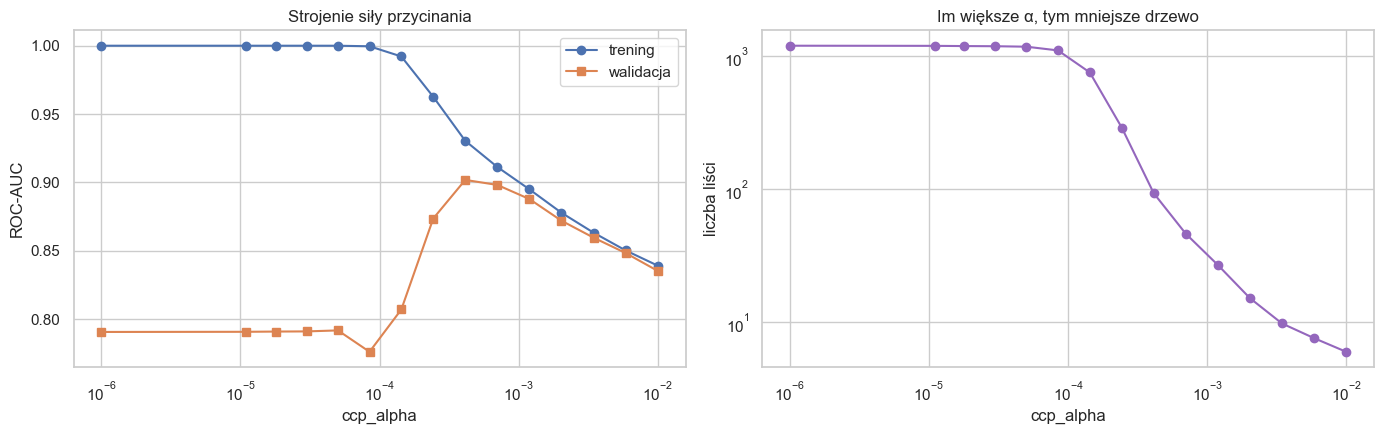

najlepsze α = 0.00041:  ROC-AUC walidacja 0.9019,  ok. 94 liści


In [62]:
alfy = np.r_[0, np.geomspace(1e-5, 1e-2, 14)]
wyniki_alfa = []
for a in alfy:
    m = make_pipeline(preprocessing_drzewa(), DecisionTreeClassifier(ccp_alpha=a, random_state=RANDOM_STATE))
    r = cross_validate(m, X_hot, y_hot, cv=cv_hot, scoring="roc_auc", return_train_score=True, return_estimator=True, n_jobs=-1)
    wyniki_alfa.append({"alfa": a, "trening": r["train_score"].mean(), "walidacja": r["test_score"].mean(),
                        "liście": np.mean([e[-1].get_n_leaves() for e in r["estimator"]])})
wyniki_alfa = pd.DataFrame(wyniki_alfa)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(wyniki_alfa["alfa"] + 1e-6, wyniki_alfa["trening"], "o-", label="trening")
ax[0].plot(wyniki_alfa["alfa"] + 1e-6, wyniki_alfa["walidacja"], "s-", label="walidacja")
ax[0].set_xscale("log"); ax[0].set_xlabel("ccp_alpha"); ax[0].set_ylabel("ROC-AUC"); ax[0].legend()
ax[0].set_title("Strojenie siły przycinania")
ax[1].plot(wyniki_alfa["alfa"] + 1e-6, wyniki_alfa["liście"], "o-", color="tab:purple")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("ccp_alpha"); ax[1].set_ylabel("liczba liści")
ax[1].set_title("Im większe α, tym mniejsze drzewo")
plt.tight_layout(); plt.show()
najl = wyniki_alfa.loc[wyniki_alfa["walidacja"].idxmax()]
print(f"najlepsze α = {najl['alfa']:.5f}:  ROC-AUC walidacja {najl['walidacja']:.4f},  ok. {najl['liście']:.0f} liści")

Obraz lustrzany wykresu z Ridge na Zajęciach 1: α = 0 → przeuczenie, za duże α → drzewo z kilkoma liśćmi i niedouczenie, a optimum pośrodku.

### 4.3 `GridSearchCV` — strojenie hiperparametrów bez pisania pętli

Do tej pory pętle pisaliśmy sami. `GridSearchCV` robi to samo: dla **każdej kombinacji** z siatki liczy CV i wybiera najlepszą. Trzy zasady, które już znacie:
* **cały pipeline** wchodzi do środka (zero leakage) — parametry kroków podajemy jako `nazwa_kroku__parametr`,
* ten sam obiekt `cv` co wszędzie,
* `scoring` = metryka wybrana do problemu.

In [63]:
from sklearn.model_selection import GridSearchCV

pipe_drzewo = Pipeline([
    ("preprocessing", preprocessing_drzewa()),
    ("drzewo", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
siatka_param = {
    "drzewo__max_depth": [4, 6, 8, 10, 12, None],
    "drzewo__min_samples_leaf": [1, 5, 20, 50],
}
gs = GridSearchCV(pipe_drzewo, siatka_param, cv=cv_hot, scoring="roc_auc", n_jobs=-1)
gs.fit(X_hot, y_hot)

print("najlepsze parametry:", gs.best_params_)
print(f"najlepszy wynik CV:   {gs.best_score_:.4f}")
print(f"przeszukano {len(gs.cv_results_['params'])} kombinacji × {cv_hot.get_n_splits()} foldów = {len(gs.cv_results_['params']) * cv_hot.get_n_splits()} treningów")

najlepsze parametry: {'drzewo__max_depth': 12, 'drzewo__min_samples_leaf': 20}
najlepszy wynik CV:   0.8964
przeszukano 24 kombinacji × 5 foldów = 120 treningów


In [64]:
wyniki_gs = (pd.DataFrame(gs.cv_results_)
             [["param_drzewo__max_depth", "param_drzewo__min_samples_leaf", "mean_test_score", "std_test_score", "rank_test_score"]]
             .sort_values("rank_test_score"))
wyniki_gs.head(8).round(4)

,param_drzewo__max_depth,param_drzewo__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
18,12,20,0.8964,0.0057,1
22,None,20,0.8936,0.0062,2
14,10,20,0.8933,0.0068,3
13,10,5,0.8930,0.0053,4
12,10,1,0.8929,0.0065,5
19,12,50,0.8929,0.0050,6
23,None,50,0.8925,0.0046,7
15,10,50,0.8924,0.0046,8


**Czytamy jak na Zajęciach 2:** kilka pierwszych kombinacji różni się o mniej niż jedno odchylenie standardowe — to **remis**. Przy remisie bierzemy **prostszy** model (płytsze drzewo, większy liść): jest stabilniejszy i łatwiejszy do wyjaśnienia.

Przycinanie `ccp_alpha` z sekcji 4.2 dało prawie ten sam wynik (różnica mniejsza niż odchylenie między foldami) — to remis. W praktyce zwykle wybieramy **pre-pruning** (`max_depth`, `min_samples_leaf`): parametry są intuicyjne, strojenie jest tańsze, a te same parametry wrócą w lasach i boostingu. `ccp_alpha` przydaje się, gdy końcowym modelem ma być jedno, możliwie małe drzewo.

Po przeszukaniu `GridSearchCV` domyślnie trenuje najlepszy wariant na **całych danych** (`refit=True`) — gotowy model jest w `gs.best_estimator_`.

In [65]:
najlepsze_drzewo_hot = gs.best_estimator_
ocen("drzewo nastrojone (GridSearchCV)", najlepsze_drzewo_hot, X_hot, y_hot, cv_hot, "roc_auc", "hotele")

gs_kal = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE),
                      {"max_depth": [6, 8, 10, 12, None], "min_samples_leaf": [5, 10, 20, 50]},
                      cv=cv_kal, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_kal, y_kal)
print("California — najlepsze:", gs_kal.best_params_)
ocen("drzewo nastrojone (GridSearchCV)", gs_kal.best_estimator_, X_kal, y_kal, cv_kal, "neg_root_mean_squared_error", "kalifornia");

drzewo nastrojone (GridSearchCV)              roc_auc: 0.8964 ± 0.0057   (trening: 0.9283)
California — najlepsze: {'max_depth': None, 'min_samples_leaf': 20}
drzewo nastrojone (GridSearchCV)              root_mean_squared_error: 0.6145 ± 0.0172   (trening: 0.5085)


---
## 5. Co drzewo daje „za darmo”, a czego nie umie

### 5.1 Skala i transformacje monotoniczne — bez znaczenia

In [66]:
drzewo_kred = lambda: DecisionTreeClassifier(min_samples_leaf=100, random_state=RANDOM_STATE)

warianty = {
    "drzewo: surowe dane (z NaN!)": drzewo_kred(),
    "drzewo: + StandardScaler": make_pipeline(StandardScaler(), drzewo_kred()),
    "drzewo: + log1p": make_pipeline(FunctionTransformer(np.log1p), drzewo_kred())
    }
for nazwa, m in warianty.items():
    ocen(nazwa, m, X_kred, y_kred, cv_kred, "average_precision", "kredyty", pokaz=True)
TABELA = TABELA[:-3]   # zostawiamy w tabeli tylko wariant „surowe dane”

drzewo: surowe dane (z NaN!)                  average_precision: 0.3325 ± 0.0173   (trening: 0.3848)
drzewo: + StandardScaler                      average_precision: 0.3324 ± 0.0172   (trening: 0.3848)
drzewo: + log1p                               average_precision: 0.3325 ± 0.0173   (trening: 0.3848)


* **Skalowanie i `log1p` — wynik identyczny** (PR-AUC 0.3325 we wszystkich trzech wariantach). Drzewo pyta tylko „x ≤ próg?”, a te transformacje nie zmieniają **kolejności** obserwacji — więc podziały są te same.
* **Bez imputera** — drzewo przyjmuje `NaN` i samo uczy się, w którą stronę wysłać brak.
* **Porównanie z Zajęciami 2:** regresja logistyczna potrzebowała całej tej pracy, żeby wejść z ok. 0.23 na ok. 0.35. Drzewo na **surowych** danych startuje od razu z ok. 0.33.

**Wniosek:** walka ze skalą w cechach to głównie problem modeli liniowych. Zrozumienie danych (błędy, kody 96/98, nowe cechy) nadal jest potrzebne — przy każdym modelu.

### 5.2 Kategorie: `OrdinalEncoder` wystarczy

Dla modelu liniowego kodowanie porządkowe kategorii bez porządku było błędem (model zakłada, że „kod 3 = 3 × kod 1”). Drzewo **nie mnoży** przez kod — zadaje pytania „kod ≤ 1.5?”, a kilkoma pytaniami potrafi wydzielić dowolną kategorię (jak „Non Refund” w sekcji 1).

In [67]:
pre_onehot = ColumnTransformer(
    [("kategorie", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False), CECHY_KAT)],
    remainder="passthrough", verbose_feature_names_out=False)
parametry = {k.replace("drzewo__", ""): v for k, v in gs.best_params_.items()}

for nazwa, pre in [("OrdinalEncoder", preprocessing_drzewa()), ("OneHotEncoder", pre_onehot)]:
    m = make_pipeline(pre, DecisionTreeClassifier(**parametry, random_state=RANDOM_STATE))
    r = cross_validate(m, X_hot, y_hot, cv=cv_hot, scoring="roc_auc", n_jobs=-1)
    print(f"drzewo + {nazwa:<15} ROC-AUC: {r['test_score'].mean():.4f} ± {r['test_score'].std():.4f}   "
          f"liczba kolumn: {m.fit(X_hot, y_hot)[0].transform(X_hot.head()).shape[1]}")

drzewo + OrdinalEncoder  ROC-AUC: 0.8964 ± 0.0057   liczba kolumn: 22
drzewo + OneHotEncoder   ROC-AUC: 0.8999 ± 0.0050   liczba kolumn: 166


Różnica mieści się w szumie, a `OrdinalEncoder` daje **22 kolumny zamiast ok. 170** — drzewo trenuje się szybciej, a reguły są czytelniejsze.

### 5.3 Nieliniowości i interakcje — same

Wróćmy do tabeli. W California nastrojone drzewo (sekcja 4.3) bije zarówno regresję liniową, jak i GAM z Zajęć 1 — **bez** splajnów, skalowania i ręcznie robionych cech:

In [68]:
pd.DataFrame(TABELA).query("zbiór == 'kalifornia'").set_index("model").round(4)

,zbiór,metryka,walidacja,± std,trening
model,,,,,
Dummy,kalifornia,root_mean_squared_error,1.1542,0.0213,1.1543
regresja liniowa,kalifornia,root_mean_squared_error,0.7216,0.0184,0.7164
GAM: splajny + Ridge (Zajęcia 1),kalifornia,root_mean_squared_error,0.6658,0.0153,0.6604
drzewo nastrojone (GridSearchCV),kalifornia,root_mean_squared_error,0.6145,0.0172,0.5085


### 5.4 Czego drzewo nie umie

**(a) Ekstrapolacja.** Poza zakresem danych treningowych drzewo zwraca wartość ze skrajnego liścia — **płaska linia**. Model liniowy przynajmniej kontynuuje trend.

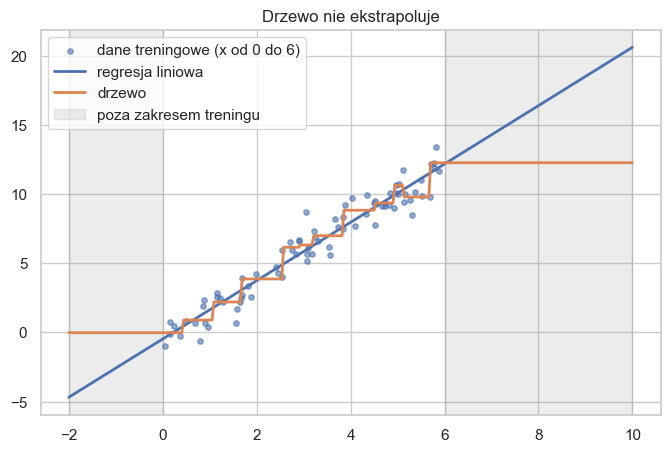

In [69]:
# prosty trend: y rośnie liniowo z x; trenujemy tylko na x z [0, 6]
rng_e = np.random.default_rng(1)
Xe = rng_e.uniform(0, 6, size=(80, 1))
ye = 2 * Xe.ravel() + rng_e.normal(0, 1, size=80)
siatka_e = np.linspace(-2, 10, 300).reshape(-1, 1)

plt.scatter(Xe, ye, s=15, alpha=0.6, label="dane treningowe (x od 0 do 6)")
plt.plot(siatka_e, LinearRegression().fit(Xe, ye).predict(siatka_e), lw=2, label="regresja liniowa")
plt.plot(siatka_e, DecisionTreeRegressor(min_samples_leaf=5).fit(Xe, ye).predict(siatka_e), lw=2, label="drzewo")
plt.axvspan(-2, 0, color="gray", alpha=0.15); plt.axvspan(6, 10, color="gray", alpha=0.15, label="poza zakresem treningu")
plt.title("Drzewo nie ekstrapoluje"); plt.legend(); plt.show()

**(b) Ukośne granice → schodki.** Każde cięcie jest prostopadłe do osi. Granica „x₂ > x₁” dla modelu liniowego to jedna prosta, a dla drzewa — schody:

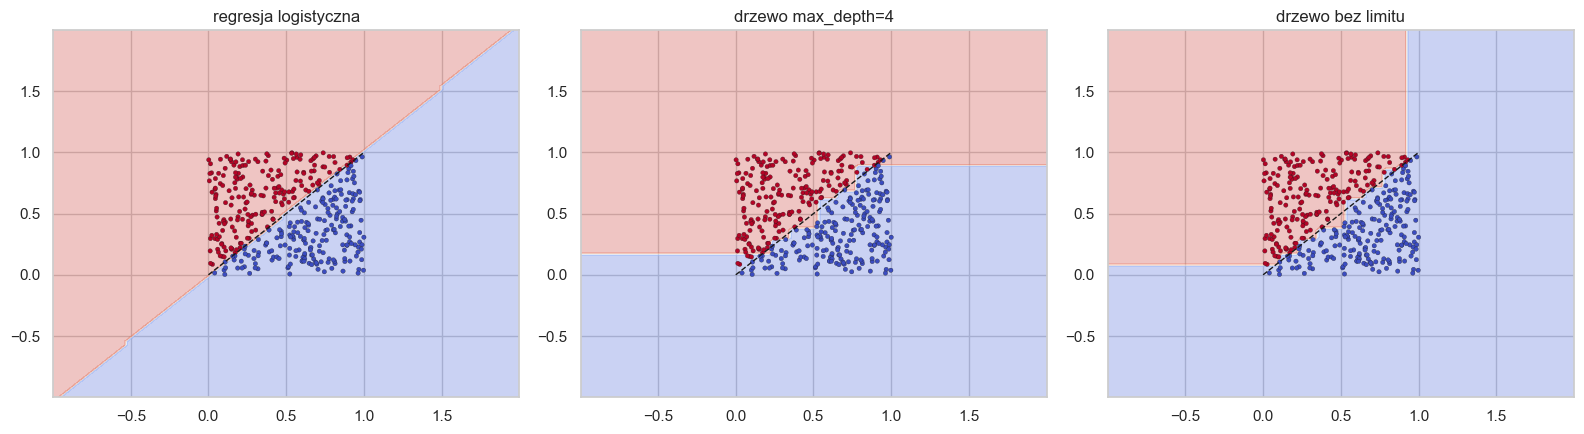

In [70]:
from sklearn.inspection import DecisionBoundaryDisplay

rng_u = np.random.default_rng(2)
Xu = rng_u.uniform(0, 1, size=(400, 2))
yu = (Xu[:, 1] > Xu[:, 0]).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nazwa, m) in zip(axes, [("regresja logistyczna", LogisticRegression()),
                                 ("drzewo max_depth=4", DecisionTreeClassifier(max_depth=4, random_state=0)),
                                 ("drzewo bez limitu", DecisionTreeClassifier(random_state=0))]):
    m.fit(Xu, yu)
    DecisionBoundaryDisplay.from_estimator(m, Xu, response_method="predict", ax=ax, alpha=0.3, cmap="coolwarm")
    ax.scatter(Xu[:, 0], Xu[:, 1], c=yu, cmap="coolwarm", s=10, edgecolor="k", linewidth=0.2)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(nazwa)
plt.tight_layout(); plt.show()

**(c) Zgrubne prawdopodobieństwa.** `predict_proba` drzewa to odsetek klas w liściu — drzewo o 32 liściach daje **co najwyżej 32 różne wartości p**. Wielu klientów dostaje identyczne PD, a krzywe ROC/PR mają mało punktów.

In [71]:
d5 = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE).fit(X_kred, y_kred)
p = d5.predict_proba(X_kred)[:, 1]
print(f"drzewo głębokości 5: {d5.get_n_leaves()} liści  ->  {len(np.unique(p))} różnych wartości PD dla {len(p):,} klientów")
print(f"regresja logistyczna:            ->  {len(np.unique(lr_kredyty_najlepsze.fit(X_kred, y_kred).predict_proba(X_kred)[:, 1])):,} różnych wartości PD")

drzewo głębokości 5: 32 liści  ->  29 różnych wartości PD dla 30,000 klientów
regresja logistyczna:            ->  29,933 różnych wartości PD


**(d) Niestabilność** — z sekcji 3.3. To jest wada numer jeden.

**Ale za to (e) — interpretowalność:** małe drzewo to zestaw reguł, który można pokazać managerowi lub regulatorowi i sprawdzić ręcznie (`export_text`).

**Drzewo decyzyjne — bilans**

| obszar | ✅ zalety | ❌ wady |
|---|---|---|
| **skala cech** | bez skalowania — liczy się tylko kolejność wartości | — |
| **outliery w cechach** | odporne — skrajna wartość trafia po prostu do skrajnego liścia | — |
| **braki** | natywna obsługa `NaN` — bez imputera | — |
| **kategorie** | wystarczy `OrdinalEncoder` | w sklearn nie da się podać tekstu wprost — trzeba zakodować |
| **nieliniowości i interakcje** | potrafi złapać je sam (geografia w California) | — |
| **kształt granic** | — | tylko cięcia prostopadłe do osi → **schodki** zamiast ukośnej linii |
| **ekstrapolacja** | — | **brak** — poza zakresem treningu zwraca wartość ze skrajnego liścia |
| **stabilność** | — | **wysoka wariancja** — mała zmiana danych → inne drzewo (38% niezgodnych decyzji) |
| **prawdopodobieństwa** | — | **zgrubne** — tyle różnych p, ile liści; głębokie drzewo daje prawie same 0 i 1 |
| **przeuczenie** | łatwe do kontroli: `max_depth`, `min_samples_leaf`, `ccp_alpha` | bez ograniczeń zapamiętuje trening (ROC-AUC na treningu = 1.0) |
| **interpretowalność** | małe drzewo = czytelne reguły (`export_text`) dla managera czy regulatora | duże drzewo (setki liści) jest już nieczytelne |
| **jakość predykcji** | dobry punkt wyjścia bez preprocessingu | samo zwykle przegrywa z dobrym modelem liniowym i z zespołami drzew |

---
## 6. Podsumowanie — i most do części 2

Dopiszmy nastrojone drzewo dla kredytów i zbierzmy wszystko w jednej tabeli:

In [72]:
gs_kred = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                       {"max_depth": [4, 5, 6, 8, None], "min_samples_leaf": [20, 50, 100, 200]},
                       cv=cv_kred, scoring="average_precision", n_jobs=-1).fit(X_kred, y_kred)
print("kredyty — najlepsze:", gs_kred.best_params_)
ocen("drzewo nastrojone (GridSearchCV)", gs_kred.best_estimator_, X_kred, y_kred, cv_kred, "average_precision", "kredyty")

podsumowanie = (pd.DataFrame(TABELA).sort_values("zbiór", kind="stable")
                .set_index(["zbiór", "metryka", "model"]))
podsumowanie.round(4)

kredyty — najlepsze: {'max_depth': 8, 'min_samples_leaf': 100}
drzewo nastrojone (GridSearchCV)              average_precision: 0.3341 ± 0.0164   (trening: 0.3720)


walidacja  \
zbiór      metryka                 model                                                      
hotele     roc_auc                 Dummy                                             0.5000   
                                   regresja logistyczna (Zajęcia 1–2)                0.9095   
                                   drzewo nastrojone (GridSearchCV)                  0.8964   
kalifornia root_mean_squared_error Dummy                                             1.1542   
                                   regresja liniowa                                  0.7216   
                                   GAM: splajny + Ridge (Zajęcia 1)                  0.6658   
                                   drzewo nastrojone (GridSearchCV)                  0.6145   
kredyty    average_precision       Dummy                                             0.0668   
                                   LR: surowe dane (mediana + skalowanie)            0.2260   
                                   LR: najlepsze z Zajęć 2 (kody + winsoryzacja)     0.3542   
                                   drzewo nastrojone (GridSearchCV)                  0.3341   

                                                                                   ± std  \
zbiór      metryka                 model                                                   
hotele     roc_auc                 Dummy                                          0.0000   
                                   regresja logistyczna (Zajęcia 1–2)             0.0057   
                                   drzewo nastrojone (GridSearchCV)               0.0057   
kalifornia root_mean_squared_error Dummy                                          0.0213   
                                   regresja liniowa                               0.0184   
                                   GAM: splajny + Ridge (Zajęcia 1)               0.0153   
                                   drzewo nastrojone (GridSearchCV)               0.0172   
kredyty    average_precision       Dummy                                          0.0000   
                                   LR: surowe dane (mediana + skalowanie)         0.0079   
                                   LR: najlepsze z Zajęć 2 (kody + winsoryzacja)  0.0145   
                                   drzewo nastrojone (GridSearchCV)               0.0164   

                                                                                  trening  
zbiór      metryka                 model                                                   
hotele     roc_auc                 Dummy                                           0.5000  
                                   regresja logistyczna (Zajęcia 1–2)              0.9164  
                                   drzewo nastrojone (GridSearchCV)                0.9283  
kalifornia root_mean_squared_error Dummy                                           1.1543  
                                   regresja liniowa                                0.7164  
                                   GAM: splajny + Ridge (Zajęcia 1)                0.6604  
                                   drzewo nastrojone (GridSearchCV)                0.5085  
kredyty    average_precision       Dummy                                           0.0668  
                                   LR: surowe dane (mediana + skalowanie)          0.2277  
                                   LR: najlepsze z Zajęć 2 (kody + winsoryzacja)   0.3547  
                                   drzewo nastrojone (GridSearchCV)                0.3720

**Co widzimy:**
* **California:** drzewo wyraźnie wygrywa z modelami liniowymi — dane są geograficzne, pełne interakcji.
* **Hotele:** nastrojone drzewo jest **odrobinę gorsze** od regresji logistycznej z dobrym preprocessingiem (ok. 0.90 vs 0.91 ROC-AUC).
* **Kredyty:** drzewo na **surowych** danych (ok. 0.33) jest dużo lepsze niż regresja logistyczna na surowych danych (ok. 0.23), ale nie dogania jej wersji po całej pracy z Zajęć 2 (ok. 0.35).

**Most do części 2 — dwie drogi naprawy:**

| | pomysł | co zmniejsza |
|---|---|---|
| **bagging** | wytrenuj **wiele głębokich drzew** na różnych próbkach i **uśrednij** | wariancję |
| **boosting** | buduj **małe drzewa po kolei** — każde poprawia błędy poprzednich | bias |

**Ściąga:**

| potrzeba | narzędzie |
|---|---|
| drzewo klasyfikacyjne / regresyjne | `DecisionTreeClassifier`, `DecisionTreeRegressor` |
| podgląd struktury | `plot_tree`, `export_text`, `.get_n_leaves()`, `.get_depth()` |
| kontrola złożoności | `max_depth`, `min_samples_leaf`, `max_leaf_nodes`, `ccp_alpha` |
| kategorie dla drzewa | `OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)` |
| strojenie | `GridSearchCV(pipeline, {"krok__parametr": [...]}, cv=cv, scoring=...)`, `.best_params_`, `.cv_results_`, `.best_estimator_` |